In [6]:
pip install seaborn joblib xgboost

^C
Note: you may need to restart the kernel to use updated packages.


# AIR-SHIELD — 03: Pollution Forecasting

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

try:
    from xgboost import XGBRegressor
    HAS_XGB = True
except ImportError:
    HAS_XGB = False
    print("xgboost not installed — will skip XGBoost and rely on RandomForest/GradientBoosting.")

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

CLEAN_PATH = "D:\\AI_EDUCATOR\\Project\\AIR_SHIELD\\AIR_SHIELD\\data\\processed\\cleaned_air_quality.csv"
MODEL_DIR = "D:\\AI_EDUCATOR\\Project\\AIR_SHIELD\\AIR_SHIELD\\models"
os.makedirs(MODEL_DIR, exist_ok=True)


## 1. Load cleaned data

In [12]:
df = pd.read_csv(CLEAN_PATH, parse_dates=["Date"])
df = df.sort_values(["City", "Date"]).reset_index(drop=True)
print(df.shape)
df.head()


(29531, 17)


,City,Date,PM2.5,PM10,NO,NO2,NOx,CO,SO2,O3,AQI,AQI_Bucket,Year,Month,Day,DayOfWeek,Season
0,Ahmedabad,2015-01-01,73.24,141.54,0.92,18.22,17.15,0.92,27.64,133.36,209.0,Poor,2015,1,1,Thursday,Winter
1,Ahmedabad,2015-01-02,73.24,141.54,0.97,15.69,16.46,0.97,24.55,34.06,209.0,Poor,2015,1,2,Friday,Winter
2,Ahmedabad,2015-01-03,73.24,141.54,17.40,19.30,29.70,17.40,29.07,30.70,209.0,Poor,2015,1,3,Saturday,Winter
3,Ahmedabad,2015-01-04,73.24,141.54,1.70,18.48,17.97,1.70,18.59,36.08,209.0,Poor,2015,1,4,Sunday,Winter
4,Ahmedabad,2015-01-05,73.24,141.54,22.10,21.42,37.76,22.10,39.33,39.31,209.0,Poor,2015,1,5,Monday,Winter


## 2. Feature engineering — lag features & rolling averages

In [9]:
pollutant_cols = ["PM2.5", "PM10", "NO", "NO2", "NOx", "NH3", "CO",
                   "SO2", "O3", "Benzene", "Toluene", "Xylene"]
pollutant_cols = [c for c in pollutant_cols if c in df.columns]

FEATURE_COLS = pollutant_cols + ["AQI"]
LAGS = [1, 2, 3, 7]
ROLL_WINDOWS = [3, 7, 14]

def add_time_series_features(g):
    g = g.copy()
    for col in FEATURE_COLS:
        for lag in LAGS:
            g[f"{col}_lag{lag}"] = g[col].shift(lag)
        for win in ROLL_WINDOWS:
            g[f"{col}_roll{win}_mean"] = g[col].shift(1).rolling(win).mean()
    return g

df = df.groupby("City", group_keys=False).apply(add_time_series_features)

# Calendar features already exist from Person 1 (Year, Month, Day, DayOfWeek, Season);
# one-hot encode the categorical ones for modeling.
df = pd.get_dummies(df, columns=["Season", "DayOfWeek"], drop_first=True)

print("Feature-engineered shape:", df.shape)


Feature-engineered shape: (29531, 86)


## 3. Define the forecasting target: next-day AQI

In [13]:
df["AQI_next"] = df.groupby("City")["AQI"].shift(-1)

model_df = df.dropna(subset=["AQI_next"]).copy()

lag_roll_cols = [c for c in model_df.columns if "_lag" in c or "_roll" in c]
season_dow_cols = [c for c in model_df.columns if c.startswith("Season_") or c.startswith("DayOfWeek_")]

model_df = pd.get_dummies(model_df, columns=["City"], prefix="City")
city_cols = [c for c in model_df.columns if c.startswith("City_")]

FEATURES = lag_roll_cols + season_dow_cols + city_cols + ["Month", "Day"]
FEATURES = [c for c in FEATURES if c in model_df.columns]

model_df = model_df.dropna(subset=FEATURES) 
print("Modeling rows:", model_df.shape[0], " | Features:", len(FEATURES))


Modeling rows: 29505  | Features: 28


## 4. Time-aware train/test split



In [14]:
split_date = model_df["Date"].quantile(0.8, interpolation="nearest")
print("Split date:", split_date)

train = model_df[model_df["Date"] <= split_date]
test = model_df[model_df["Date"] > split_date]

X_train, y_train = train[FEATURES], train["AQI_next"]
X_test, y_test = test[FEATURES], test["AQI_next"]

print("Train rows:", len(X_train), " Test rows:", len(X_test))


Split date: 2019-11-06 00:00:00
Train rows: 23620  Test rows: 5885


## 5. Train baseline and advanced models

In [15]:
models = {
    "LinearRegression": LinearRegression(),
    "RandomForest": RandomForestRegressor(n_estimators=300, max_depth=12, random_state=42, n_jobs=-1),
    "GradientBoosting": GradientBoostingRegressor(n_estimators=300, max_depth=4, learning_rate=0.05, random_state=42),
}
if HAS_XGB:
    models["XGBoost"] = XGBRegressor(
        n_estimators=400, max_depth=6, learning_rate=0.05,
        subsample=0.8, colsample_bytree=0.8, random_state=42, n_jobs=-1
    )

results = []
fitted_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)

    mae = mean_absolute_error(y_test, preds)
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    r2 = r2_score(y_test, preds)

    results.append({"model": name, "MAE": mae, "RMSE": rmse, "R2": r2})
    fitted_models[name] = model
    print(f"{name:>18s} | MAE={mae:8.2f}  RMSE={rmse:8.2f}  R2={r2:6.3f}")

results_df = pd.DataFrame(results).sort_values("RMSE")
results_df


  LinearRegression | MAE=   65.72  RMSE=   90.85  R2= 0.088
      RandomForest | MAE=   65.03  RMSE=   89.31  R2= 0.118
  GradientBoosting | MAE=   63.10  RMSE=   85.37  R2= 0.194
           XGBoost | MAE=   64.89  RMSE=   88.31  R2= 0.138


,model,MAE,RMSE,R2
2,GradientBoosting,63.098608,85.373394,0.194264
3,XGBoost,64.885073,88.309177,0.137897
1,RandomForest,65.029155,89.313956,0.118167
0,LinearRegression,65.724419,90.850036,0.087574


## 6. Select and save the best model

In [16]:
best_name = results_df.iloc[0]["model"]
best_model = fitted_models[best_name]
print("Best model:", best_name)

joblib.dump(best_model, f"{MODEL_DIR}/best_forecast_model.pkl")
joblib.dump(FEATURES, f"{MODEL_DIR}/forecast_features.pkl")
print(f"Saved: {MODEL_DIR}/best_forecast_model.pkl")


Best model: GradientBoosting
Saved: D:\AI_EDUCATOR\Project\AIR_SHIELD\AIR_SHIELD\models/best_forecast_model.pkl


## 7. Visualize forecast quality

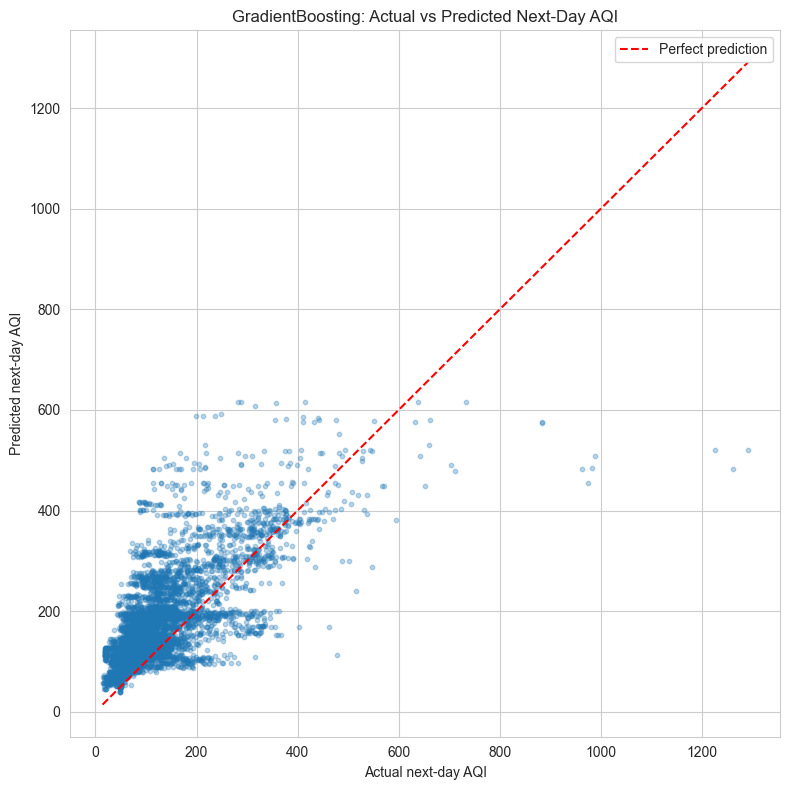

In [17]:
preds_best = best_model.predict(X_test)

plt.figure(figsize=(8, 8))
plt.scatter(y_test, preds_best, alpha=0.3, s=10)
lims = [min(y_test.min(), preds_best.min()), max(y_test.max(), preds_best.max())]
plt.plot(lims, lims, "r--", label="Perfect prediction")
plt.xlabel("Actual next-day AQI")
plt.ylabel("Predicted next-day AQI")
plt.title(f"{best_name}: Actual vs Predicted Next-Day AQI")
plt.legend()
plt.tight_layout()
plt.show()


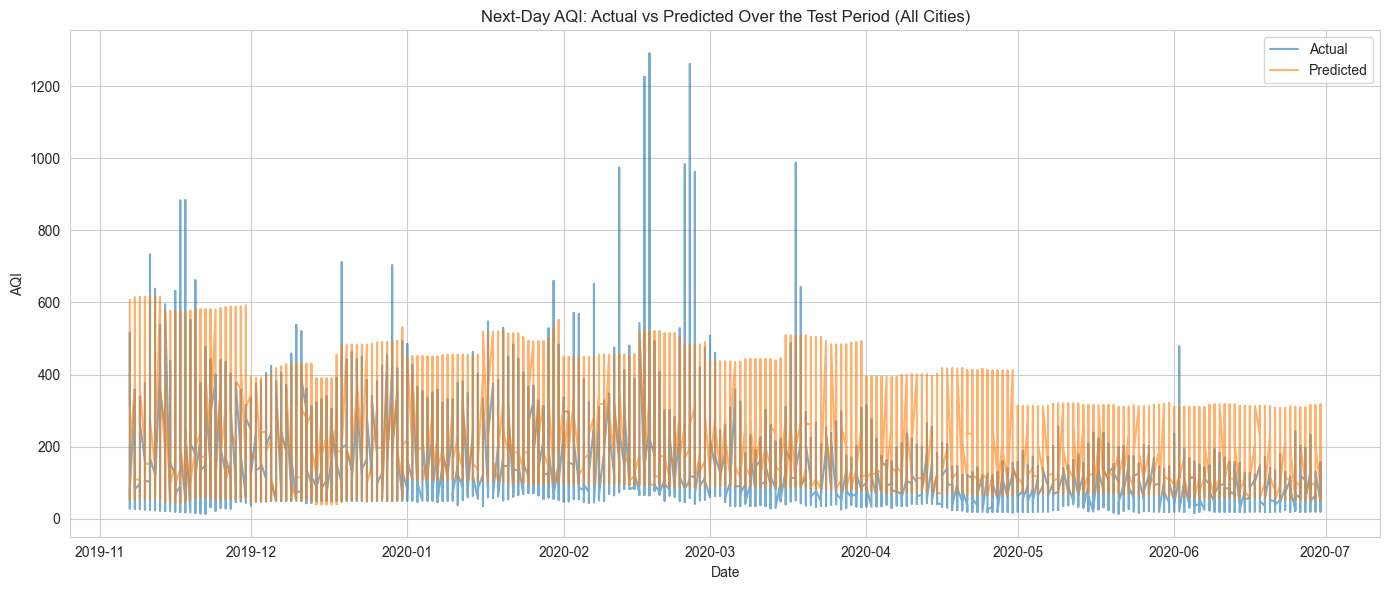

In [18]:
test_plot = test[["Date"]].copy()
test_plot["Actual"] = y_test.values
test_plot["Predicted"] = preds_best
test_plot = test_plot.sort_values("Date")

plt.figure(figsize=(14, 6))
plt.plot(test_plot["Date"], test_plot["Actual"], label="Actual", alpha=0.6)
plt.plot(test_plot["Date"], test_plot["Predicted"], label="Predicted", alpha=0.6)
plt.title("Next-Day AQI: Actual vs Predicted Over the Test Period (All Cities)")
plt.xlabel("Date")
plt.ylabel("AQI")
plt.legend()
plt.tight_layout()
plt.show()


## 8. Save forecast results for the dashboard (Person 4)

In [19]:
output_cols_source = df.loc[test.index, ["City", "Date"]].reset_index(drop=True)
forecast_results = pd.concat(
    [output_cols_source,
     pd.Series(y_test.values, name="Actual_AQI"),
     pd.Series(preds_best, name="Predicted_AQI")],
    axis=1
)
forecast_results["Abs_Error"] = (forecast_results["Actual_AQI"] - forecast_results["Predicted_AQI"]).abs()

os.makedirs("../data/processed", exist_ok=True)
forecast_results.to_csv("../data/processed/forecast_results.csv", index=False)
results_df.to_csv("../data/processed/forecast_model_comparison.csv", index=False)

print("Saved forecast_results.csv and forecast_model_comparison.csv")
forecast_results.head()


Saved forecast_results.csv and forecast_model_comparison.csv


,City,Date,Actual_AQI,Predicted_AQI,Abs_Error
0,Ahmedabad,2019-11-07,316.0,608.017667,292.017667
1,Ahmedabad,2019-11-08,358.0,614.055928,256.055928
2,Ahmedabad,2019-11-09,282.0,615.388098,333.388098
3,Ahmedabad,2019-11-10,289.0,616.122450,327.122450
4,Ahmedabad,2019-11-11,733.0,616.715335,116.284665
